# Echo State Networks (ESN)

## ¿Para qué sirve?

Una ESN es una red **recurrente** para trabajar con **señales que dependen del
tiempo**: predecir una serie temporal, clasificar una señal, controlar un sistema
dinámico.

La idea que la hace distinta se llama *reservoir computing*:

| | red recurrente clásica (RNN / LSTM) | Echo State Network |
|---|---|---|
| Pesos recurrentes | se entrenan | **aleatorios y fijos** |
| Pesos de salida | se entrenan | se entrenan |
| Cómo se entrena | backprop a través del tiempo (BPTT) | **regresión lineal, forma cerrada** |
| Costo | minutos u horas, gradientes que explotan o se desvanecen | segundos, sin gradientes |

El razonamiento es este: un conjunto grande de neuronas conectadas al azar
—el **reservorio**— ya genera por sí solo un montón de dinámicas ricas y no
lineales a partir de la señal de entrada. Si son suficientes y bien variadas, la
respuesta que buscamos probablemente sea una **combinación lineal** de esas
dinámicas. Entonces no hace falta entrenar la parte difícil: alcanza con aprender
a *leer* el reservorio, y eso es un problema de mínimos cuadrados con solución
exacta.

**La propiedad de eco** (*echo state property*) es la condición que hace que esto
funcione: el estado del reservorio tiene que depender de las entradas recientes y
olvidar progresivamente el pasado lejano y la condición inicial. Se controla con
el **radio espectral** de `W_rec`: si es demasiado chico el reservorio se apaga y
no tiene memoria; si es demasiado grande la dinámica se vuelve caótica e inútil.
El punto dulce está cerca de 1.

En este notebook usamos la clase de abajo para una tarea concreta: **predecir la
serie caótica de Mackey-Glass**.

## La implementación

In [1]:
import numpy as np


In [4]:
class ESN:
    """
    Echo State Network minimalista.
 
    Idea central:
    - W_in y W_rec se generan al azar UNA VEZ y quedan fijos (no se entrenan).
    - W_rec se reescala para que su radio espectral sea < 1 (o cercano a 1),
      esto es lo que da la propiedad de "echo state" (memoria estable, cerca del caos).
    - Solo se entrena W_out, y se hace con regresión lineal (ridge), no con backprop.
    """
 
    def __init__(self, n_inputs, n_reservoir, n_outputs,spectral_radius=0.9, sparsity=0.1, seed=None):
        rng = np.random.default_rng(seed)
 
        self.n_inputs = n_inputs #numero de inputs
        self.n_reservoir = n_reservoir #numeor de neuronas de ereserva
        self.n_outputs = n_outputs #numero de slaidas
 
        # --- Pesos de entrada (fijos, aleatorios) ---
        self.W_in = rng.uniform(-1, 1, size=(n_reservoir, n_inputs))
 
        # --- Pesos recurrentes del reservorio (fijos, aleatorios y dispersos) ---
        W = rng.uniform(-1, 1, size=(n_reservoir, n_reservoir))
        mask = rng.random((n_reservoir, n_reservoir)) < sparsity
        W = W * mask  # dispersión: solo una fracción de conexiones existe
 
        # --- Reescalar para fijar el radio espectral ---
        # Esto controla si la dinámica se apaga (poca memoria) o explota (caos inestable)
        eigvals = np.linalg.eigvals(W)
        radio_actual = np.max(np.abs(eigvals))
        self.W_rec = W * (spectral_radius / radio_actual)
 
        # --- Pesos de salida (esto SI se entrena) ---
        self.W_out = None #no la inicializa
 
    def _paso(self, x_prev, u):
        """Un paso de la dinámica del reservorio: x(n) = tanh(W_in*u(n) + W_rec*x(n-1))"""
        return np.tanh(self.W_in @ u + self.W_rec @ x_prev)
 
    def _recolectar_estados(self, U):
        """
        Corre toda la secuencia de entrada U a través del reservorio (sin aprender nada)
        y guarda la trayectoria x(n) de cada neurona en cada paso de tiempo.
        """
        n_steps = U.shape[0]
        X = np.zeros((n_steps, self.n_reservoir))
 
        x = np.zeros(self.n_reservoir)  # estado inicial del reservorio
        for n in range(n_steps):
            x = self._paso(x, U[n])
            X[n] = x
 
        return X
 
    def fit(self, U, D, ridge_lambda=1e-6):
        """
        Entrena la ESN.
        U: entradas, shape (n_steps, n_inputs)
        D: salidas objetivo ("teacher"), shape (n_steps, n_outputs)
 
        Lo único que se ajusta acá es W_out, vía ridge regression (forma cerrada).
        """
        X = self._recolectar_estados(U) #recolectamos estados
 
        # Ridge regression: W_out = D^T X (X^T X + lambda*I)^-1
        I = np.eye(self.n_reservoir)
        self.W_out = D.T @ X @ np.linalg.inv(X.T @ X + ridge_lambda * I) #saldia
 
        return X  # devuelvo los estados por si se quieren graficar las trayectorias
 
    def predict(self, U):
        """Genera la salida y(n) = W_out * x(n) para una nueva secuencia de entrada."""
        if self.W_out is None:
            raise RuntimeError("Primero hay que entrenar con fit().")
 
        X = self._recolectar_estados(U)
        Y = X @ self.W_out.T
        return Y
 

---
## 1. El problema: la serie de Mackey-Glass

Es el banco de pruebas clásico de las ESN. Viene de un modelo de producción de
glóbulos blancos y es una ecuación diferencial **con retardo**:

$$\frac{dx}{dt} = \beta \frac{x(t-\tau)}{1 + x(t-\tau)^{10}} - \gamma\, x(t)$$

Con $\tau = 17$ el sistema es **caótico**: parece periódico pero nunca se repite,
y dos trayectorias que arrancan casi iguales se separan exponencialmente. Eso lo
hace difícil de predecir, y por eso sirve como test.

Lo importante para nosotros: para saber cuánto vale $x(t+1)$ no alcanza con mirar
$x(t)$, hay que **acordarse** de lo que pasó 17 pasos atrás. Ahí es donde la
memoria del reservorio tiene que hacer su trabajo.

serie: 6000 pasos | min 0.369 | max 1.344


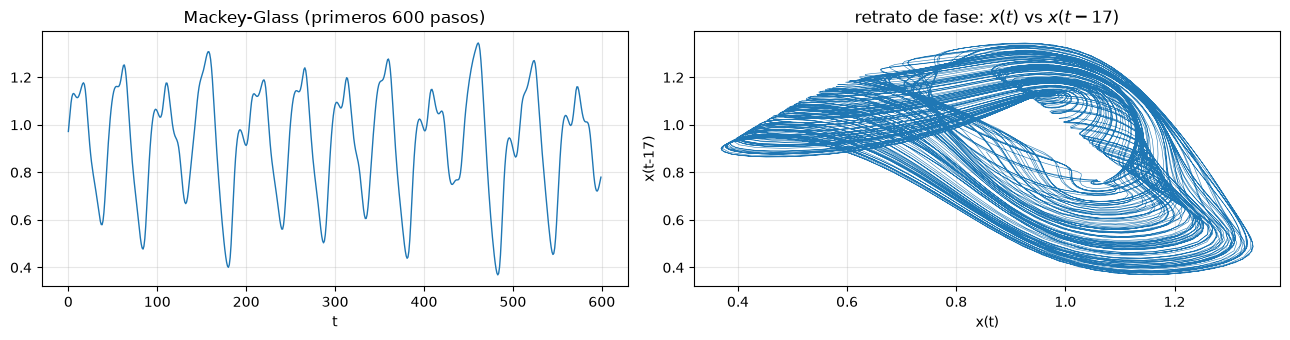

In [5]:
import matplotlib.pyplot as plt

def mackey_glass(n_steps, tau=17, beta=0.2, gamma=0.1, n=10, x0=1.2, seed=0, descarte=1000):
    """Integra la ecuación de Mackey-Glass por Euler con dt=1."""
    rng = np.random.default_rng(seed)
    total = n_steps + descarte
    x = np.zeros(total + tau)
    x[:tau] = x0 + 0.01 * rng.standard_normal(tau)      # historia inicial
    for t in range(tau, total + tau - 1):
        xt, xtau = x[t], x[t - tau]
        x[t + 1] = xt + beta * xtau / (1 + xtau**n) - gamma * xt
    return x[tau + descarte:]      # descartamos el transitorio inicial

serie = mackey_glass(6000)
print(f"serie: {serie.shape[0]} pasos | min {serie.min():.3f} | max {serie.max():.3f}")

fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
axs[0].plot(serie[:600], lw=1)
axs[0].set_title("Mackey-Glass (primeros 600 pasos)"); axs[0].set_xlabel("t")
axs[1].plot(serie[:-17], serie[17:], lw=0.4)          # retrato de fase con retardo
axs[1].set_title(r"retrato de fase: $x(t)$ vs $x(t-17)$")
axs[1].set_xlabel("x(t)"); axs[1].set_ylabel("x(t-17)")
for ax in axs: ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

El retrato de fase de la derecha muestra el **atractor extraño**: la trayectoria
nunca cierra un ciclo, pero tampoco se escapa. Se queda dando vueltas en una
región acotada, con estructura. Eso es el caos.

---
## 2. Preparar los datos

La tarea es **predicción a un paso**: entrada $u(n) = x(n)$, objetivo
$d(n) = x(n+1)$.

Dos detalles de preparación que importan bastante:

- **Normalizamos** la serie a media 0 y desvío 1. La no linealidad del reservorio
  es `tanh`, que satura fuera de $[-2, 2]$; si le metemos la señal cruda —que vive
  entre 0.4 y 1.4, toda positiva— desperdiciamos la mitad del rango dinámico.
- **Agregamos una columna de unos** a la entrada. Como `W_in` multiplica a `u`,
  esa columna constante actúa como un **bias** para cada neurona del reservorio y
  le da a cada una un punto de operación distinto sobre la `tanh`. Es un truco
  para no tener que modificar la clase, y mejora bastante el resultado.

In [6]:
mu, sigma = serie.mean(), serie.std()
s = (serie - mu) / sigma                       # normalizada

# entrada: [señal, 1] (la columna de unos hace de bias); objetivo: la señal corrida un paso
U = np.column_stack([s[:-1], np.ones(len(s) - 1)])
D = s[1:].reshape(-1, 1)

N_TRAIN, N_TEST, WASHOUT = 3000, 2000, 200

U_tr, D_tr = U[:N_TRAIN], D[:N_TRAIN]
U_te, D_te = U[N_TRAIN:N_TRAIN + N_TEST], D[N_TRAIN:N_TRAIN + N_TEST]

print("entrenamiento:", U_tr.shape, "->", D_tr.shape)
print("test:         ", U_te.shape, "->", D_te.shape)

def nrmse(y, d):
    """Error cuadrático medio normalizado por la varianza de la señal.
    0 = perfecto, 1 = tan bueno como predecir siempre la media."""
    return float(np.sqrt(np.mean((y - d)**2) / np.var(d)))

entrenamiento: (3000, 2) -> (3000, 1)
test:          (2000, 2) -> (2000, 1)


### El *washout*

Cuando el reservorio arranca, su estado es `x = 0`, que no corresponde a ninguna
historia real de la señal. Le lleva unos cuantos pasos "olvidarse" de ese arranque
artificial y entrar en régimen, que es justamente la propiedad de eco en acción.

Esos primeros estados son basura y **no hay que usarlos**: ni para ajustar `W_out`
ni para medir el error. A ese descarte se lo llama *washout*.

La clase tal como está no lo contempla (`fit` usa todos los estados), así que
agrego una función que hace lo mismo pero descartando el transitorio. De paso le
sumo **ruido a los estados** durante el entrenamiento: no cambia casi nada la
predicción a un paso, pero es imprescindible para la generación autónoma de la
sección 6. Ahí explico por qué.

In [7]:
def entrenar(esn, U, D, ridge_lambda=1e-7, washout=WASHOUT, ruido=0.0, seed=0):
    """Como esn.fit(), pero descartando el transitorio inicial y con ruido opcional."""
    rng = np.random.default_rng(seed)
    X = np.zeros((U.shape[0], esn.n_reservoir))
    x = np.zeros(esn.n_reservoir)
    for i in range(U.shape[0]):
        x = esn._paso(x, U[i])
        if ruido > 0:
            x = x + ruido * rng.standard_normal(esn.n_reservoir)
        X[i] = x

    Xw, Dw = X[washout:], D[washout:]                     # <- washout
    I = np.eye(esn.n_reservoir)
    esn.W_out = Dw.T @ Xw @ np.linalg.inv(Xw.T @ Xw + ridge_lambda * I)
    return X

---
## 3. Entrenar y predecir

Acá está la gracia del método: **no hay épocas, no hay optimizador, no hay
`backward()`**. Se corre la señal por el reservorio una sola vez, se guardan los
estados, y se resuelve un sistema lineal. Todo el entrenamiento es una llamada a
`np.linalg.inv`.

In [8]:
import time

esn = ESN(n_inputs=2, n_reservoir=400, n_outputs=1,
          spectral_radius=0.95, sparsity=0.1, seed=42)

t0 = time.time()
X_tr = entrenar(esn, U_tr, D_tr, ridge_lambda=1e-7, ruido=1e-4)
print(f"entrenamiento: {time.time() - t0:.2f} s")
print(f"parámetros entrenados: {esn.W_out.size}  "
      f"(de {esn.W_in.size + esn.W_rec.size + esn.W_out.size} totales)")

Y_te = esn.predict(U_te)
err = nrmse(Y_te[WASHOUT:], D_te[WASHOUT:])
print(f"\nNRMSE en test: {err:.5f}")

entrenamiento: 0.12 s
parámetros entrenados: 400  (de 161200 totales)

NRMSE en test: 0.00090


Fijate en el conteo de parámetros: se entrena menos del 1% de la red. Todo el
resto son números aleatorios que nunca se tocaron.

### ¿Está aprendiendo de verdad?

Un NRMSE chico no dice nada por sí solo si la tarea es fácil. Hay que compararlo
contra alternativas triviales:

- **Persistencia**: predecir $\hat{x}(n+1) = x(n)$, o sea "mañana será igual que hoy".
- **Regresión lineal directa**: la mejor recta que va de $x(n)$ a $x(n+1)$, sin
  reservorio ni memoria de ningún tipo.

Si la ESN no le gana a estos dos por varios órdenes de magnitud, el reservorio no
está aportando nada.

persistencia:      NRMSE = 0.14752
regresión lineal:  NRMSE = 0.14709
ESN:               NRMSE = 0.00090   <-- 165x mejor


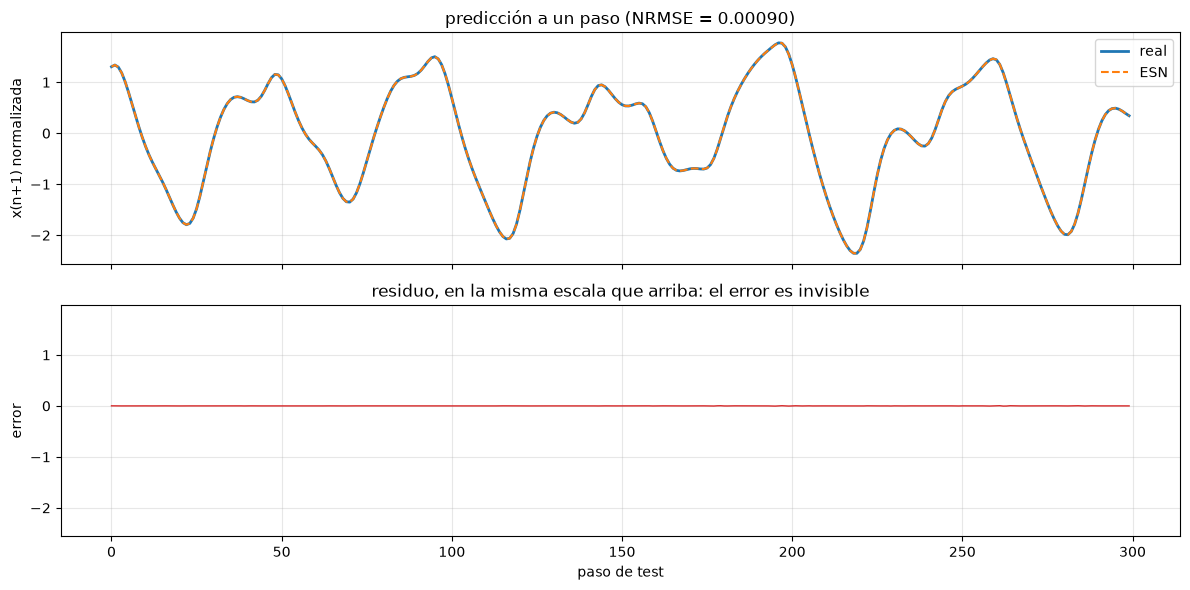

In [9]:
# baseline 1: persistencia
err_persist = nrmse(U_te[WASHOUT:, 0:1], D_te[WASHOUT:])

# baseline 2: regresión lineal sobre la entrada cruda (sin reservorio)
coef = np.linalg.lstsq(U_tr, D_tr, rcond=None)[0]
err_lineal = nrmse(U_te[WASHOUT:] @ coef, D_te[WASHOUT:])

print(f"persistencia:      NRMSE = {err_persist:.5f}")
print(f"regresión lineal:  NRMSE = {err_lineal:.5f}")
print(f"ESN:               NRMSE = {err:.5f}   <-- {err_persist/err:.0f}x mejor")

# ---- gráfico ----
ini, largo = WASHOUT, 300
t = np.arange(largo)
fig, axs = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
axs[0].plot(t, D_te[ini:ini+largo], lw=2, label="real")
axs[0].plot(t, Y_te[ini:ini+largo], "--", lw=1.5, label="ESN")
axs[0].set_ylabel("x(n+1) normalizada"); axs[0].legend(); axs[0].grid(alpha=0.3)
axs[0].set_title(f"predicción a un paso (NRMSE = {err:.5f})")

axs[1].plot(t, (Y_te[ini:ini+largo] - D_te[ini:ini+largo]), color="tab:red", lw=1)
axs[1].set_ylabel("error"); axs[1].set_xlabel("paso de test"); axs[1].grid(alpha=0.3)
axs[1].set_title("residuo, en la misma escala que arriba: el error es invisible")
axs[1].set_ylim(axs[0].get_ylim())
plt.tight_layout(); plt.show()

---
## 4. ¿Qué hay adentro del reservorio?

La clave del método es que las 400 neuronas responden a la **misma** señal de
entrada de formas **distintas**: distintas escalas de tiempo, distintos retardos,
distintos grados de saturación de la `tanh`. Es un banco de filtros no lineales
generado al azar.

`W_out` simplemente elige cuánto de cada una mezclar.

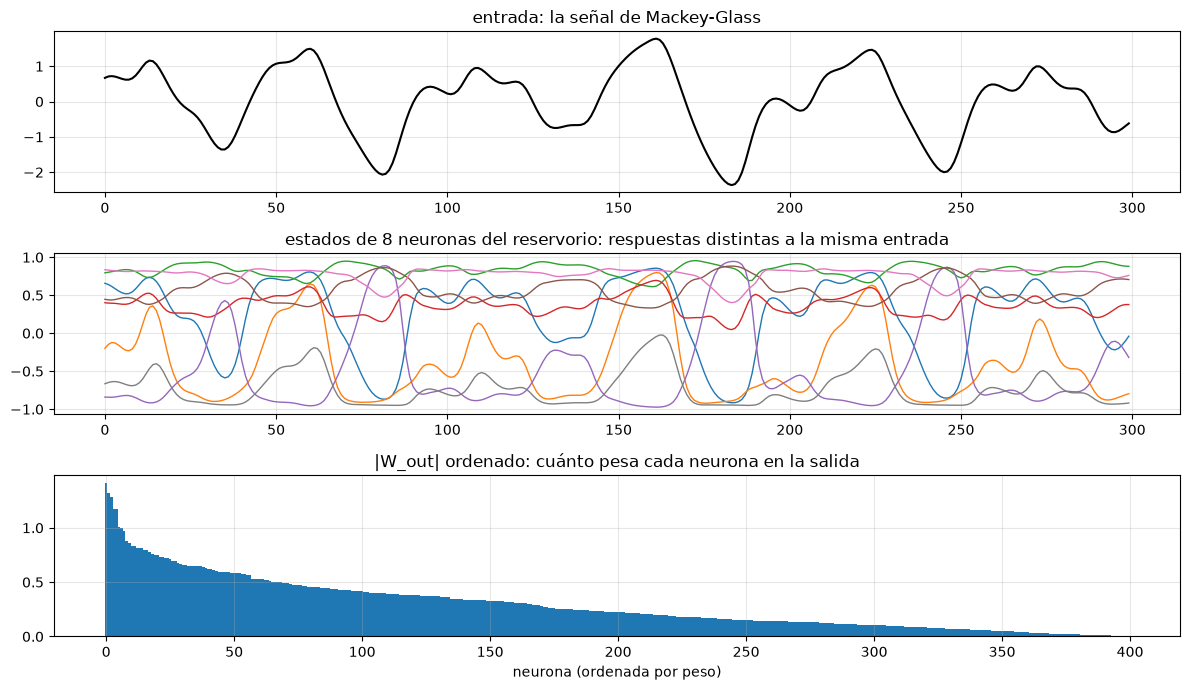

In [10]:
fig, axs = plt.subplots(3, 1, figsize=(12, 7))

axs[0].plot(s[300:600], color="k", lw=1.5)
axs[0].set_title("entrada: la señal de Mackey-Glass"); axs[0].grid(alpha=0.3)

axs[1].plot(X_tr[300:600, :8], lw=1)
axs[1].set_title("estados de 8 neuronas del reservorio: respuestas distintas a la misma entrada")
axs[1].grid(alpha=0.3)

pesos = np.abs(esn.W_out[0])
orden = np.argsort(pesos)[::-1]
axs[2].bar(range(esn.n_reservoir), pesos[orden], width=1.0)
axs[2].set_title("|W_out| ordenado: cuánto pesa cada neurona en la salida")
axs[2].set_xlabel("neurona (ordenada por peso)"); axs[2].grid(alpha=0.3)

plt.tight_layout(); plt.show()

---
## 5. Los dos hiperparámetros que importan

### Radio espectral

Es el que controla la memoria. Barremos de 0.1 —reservorio casi sin memoria, cada
entrada se olvida enseguida— a 1.5, donde la dinámica se vuelve caótica y el
reservorio genera su propio ruido tapando la señal.

### Tamaño del reservorio

Más neuronas = más funciones base para que `W_out` combine = mejor ajuste. El
costo es cúbico en la inversión de la matriz, y en algún momento aparece
sobreajuste.

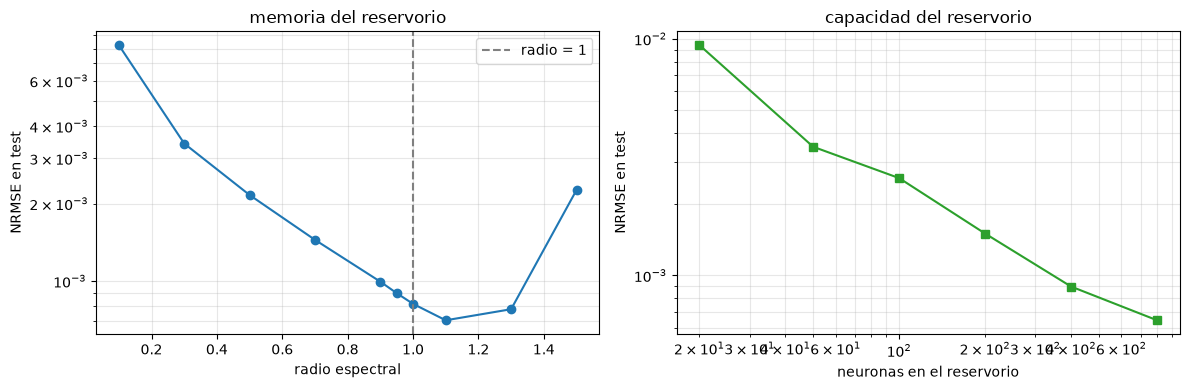

  radio 0.10 -> NRMSE 0.00825
  radio 0.30 -> NRMSE 0.00342
  radio 0.50 -> NRMSE 0.00216
  radio 0.70 -> NRMSE 0.00144
  radio 0.90 -> NRMSE 0.00099
  radio 0.95 -> NRMSE 0.00090
  radio 1.00 -> NRMSE 0.00081
  radio 1.10 -> NRMSE 0.00070
  radio 1.30 -> NRMSE 0.00078
  radio 1.50 -> NRMSE 0.00226


In [11]:
radios = [0.1, 0.3, 0.5, 0.7, 0.9, 0.95, 1.0, 1.1, 1.3, 1.5]
err_radio = []
for r in radios:
    e = ESN(2, 400, 1, spectral_radius=r, sparsity=0.1, seed=42)
    entrenar(e, U_tr, D_tr, ridge_lambda=1e-7, ruido=1e-4)
    err_radio.append(nrmse(e.predict(U_te)[WASHOUT:], D_te[WASHOUT:]))

tamanos = [20, 50, 100, 200, 400, 800]
err_tam = []
for nres in tamanos:
    e = ESN(2, nres, 1, spectral_radius=0.95, sparsity=0.1, seed=42)
    entrenar(e, U_tr, D_tr, ridge_lambda=1e-7, ruido=1e-4)
    err_tam.append(nrmse(e.predict(U_te)[WASHOUT:], D_te[WASHOUT:]))

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(radios, err_radio, marker="o")
axs[0].axvline(1.0, color="gray", ls="--", label="radio = 1")
axs[0].set_xlabel("radio espectral"); axs[0].set_ylabel("NRMSE en test")
axs[0].set_yscale("log"); axs[0].set_title("memoria del reservorio")
axs[0].legend(); axs[0].grid(alpha=0.3, which="both")

axs[1].plot(tamanos, err_tam, marker="s", color="tab:green")
axs[1].set_xlabel("neuronas en el reservorio"); axs[1].set_ylabel("NRMSE en test")
axs[1].set_xscale("log"); axs[1].set_yscale("log")
axs[1].set_title("capacidad del reservorio"); axs[1].grid(alpha=0.3, which="both")

plt.tight_layout(); plt.show()

for r, ev in zip(radios, err_radio):
    print(f"  radio {r:4.2f} -> NRMSE {ev:.5f}")

La curva de la izquierda ilustra el principio del *edge of chaos*. Con radio 0.1
el error es unas 12 veces peor que el mínimo: el reservorio se olvida de todo
enseguida y no puede reconstruir el retardo de 17 pasos que necesita la serie. El
error baja hasta un mínimo ancho entre 1.0 y 1.2, y a partir de 1.3 empieza a
empeorar. Justo en el borde de la inestabilidad es donde el reservorio tiene la
memoria más larga sin volverse caótico.

Notá que el mínimo cae un poco **por encima** de 1. La condición "radio < 1" es
una garantía suficiente pero conservadora: con una entrada que empuja al
reservorio hacia la zona saturada de la `tanh`, la dinámica efectiva se contrae
más de lo que sugiere el radio de `W_rec` sola, y en la práctica se puede pasar un
poco de 1 sin perder la propiedad de eco.

En la curva de la derecha el error cae con el tamaño, pero con **rendimientos
decrecientes**: de 20 a 50 neuronas mejora casi 3 veces, mientras que de 400 a 800
—el doble de neuronas y ocho veces el costo de inversión— mejora apenas un 30%.
La curva se aplana porque las neuronas nuevas empiezan a repetir dinámicas que el
reservorio ya tenía, y dejan de agregar información nueva para que `W_out` combine.

---
## 6. Generación autónoma: el test difícil

Hasta ahora, en cada paso le dábamos a la red el valor **real** de la serie
(*teacher forcing*). Pero una ESN entrenada para predecir el paso siguiente puede
usarse como **generador**: le realimentamos su propia predicción como entrada del
paso siguiente, y la dejamos correr sola.

Esto es mucho más exigente. Ya no hay nadie corrigiéndola: cualquier error se
realimenta y se amplifica. Si el modelo no capturó la dinámica real del sistema,
la serie generada se va al infinito o colapsa a una constante en pocos pasos.

**Por qué hace falta el ruido durante el entrenamiento.** Entrenando sin ruido, el
modelo solo vio estados generados por la señal exacta. En generación, sus propios
errores lo llevan a estados que nunca visitó, y ahí `W_out` extrapola cualquier
cosa. Inyectar ruido durante el entrenamiento le muestra estados "cercanos pero no
exactos", lo que vuelve robusta la lectura y estabiliza la generación. Sin esa
línea esta sección diverge: probalo poniendo `ruido=0` en la celda de la sección 3
y volviendo a correr.

horizonte   NRMSE
    25      0.1864
    50      0.1331
    84      0.1452
   200      0.1543
   400      0.6764
   600      0.9189


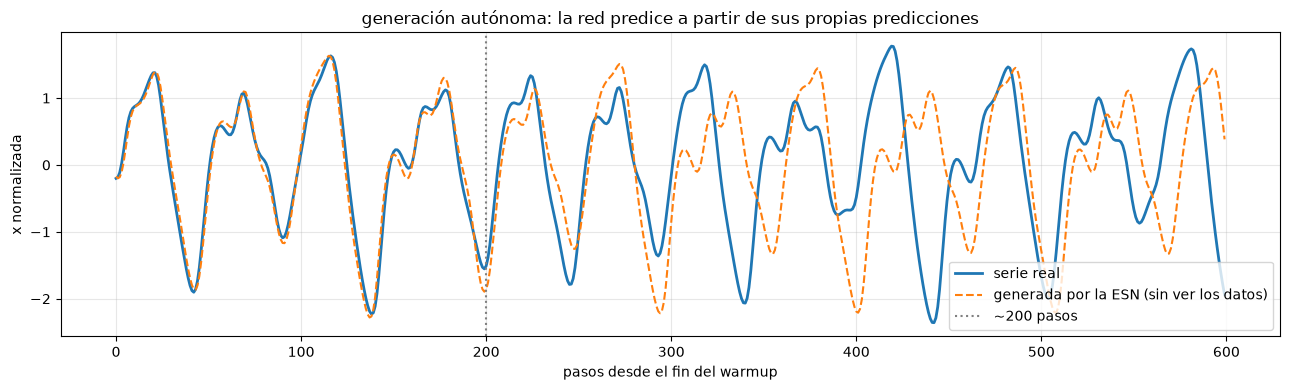

In [10]:
def generar(esn, U_warmup, n_gen):
    """Carga el reservorio con datos reales y después lo deja correr solo."""
    x = np.zeros(esn.n_reservoir)
    for u in U_warmup[:-1]:            # teacher forcing: cargar el estado
        x = esn._paso(x, u)

    u = U_warmup[-1].copy()
    salida = np.zeros((n_gen, esn.n_outputs))
    for k in range(n_gen):
        x = esn._paso(x, u)
        y = esn.W_out @ x
        salida[k] = y
        u = np.array([y[0], 1.0])      # <-- realimenta su propia predicción
    return salida

N_WARMUP, N_GEN = 600, 600
generada = generar(esn, U_te[:N_WARMUP], N_GEN)
real = D_te[N_WARMUP:N_WARMUP + N_GEN]

print("horizonte   NRMSE")
for h in [25, 50, 84, 200, 400, 600]:
    print(f"{h:6d}      {nrmse(generada[:h], real[:h]):.4f}")

plt.figure(figsize=(13, 4))
plt.plot(real, lw=2, label="serie real")
plt.plot(generada, "--", lw=1.5, label="generada por la ESN (sin ver los datos)")
plt.axvline(200, color="gray", ls=":", label="~200 pasos")
plt.xlabel("pasos desde el fin del warmup"); plt.ylabel("x normalizada")
plt.title("generación autónoma: la red predice a partir de sus propias predicciones")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Cómo leer este gráfico

Las dos curvas se superponen casi perfectamente durante unos **200 pasos** y
después se desfasan. **Eso no es una falla del modelo**: es la definición de caos.
En un sistema caótico dos trayectorias infinitesimalmente distintas se separan de
forma exponencial, así que existe un horizonte de predicción finito que ningún
modelo, por perfecto que sea, puede superar.

Lo que sí demuestra que el modelo aprendió la dinámica es que, aun después de
desfasarse, la señal generada **sigue teniendo la forma, la amplitud y la
frecuencia correctas**. No explota ni se apaga: se queda sobre el atractor. La red
no memorizó la trayectoria, capturó el sistema que la genera.

---
## 7. Resumen

**Qué es una ESN**: una red recurrente donde el reservorio es un generador
aleatorio y fijo de dinámicas no lineales, y lo único que se aprende es una
combinación lineal de esas dinámicas.

**Qué la hace atractiva**:

- El entrenamiento es una regresión lineal: solución exacta, en segundos, sin
  hiperparámetros de optimización, sin épocas y sin gradientes que se desvanezcan.
- Muy pocos hiperparámetros que ajustar: básicamente radio espectral y tamaño.
- Anda bien con pocos datos.

**Sus límites**:

- El reservorio es aleatorio, no adaptado al problema: para tareas complejas
  necesita muchas más neuronas que una LSTM entrenada.
- No escala a entradas de alta dimensión (texto, imágenes).
- Es sensible a los hiperparámetros y a la semilla; conviene promediar varias.

**Cuándo usarla**: series temporales de baja dimensión, señales de sensores,
sistemas dinámicos y control, o cuando necesitás entrenar rápido y muchas veces.
Para lenguaje o visión, no.

### Para seguir jugando

- Cambiar `seed` y ver cuánto varía el NRMSE: el reservorio es aleatorio.
- Agregarle una **tasa de fuga** (*leaking rate*) a `_paso`:
  `x = (1-a)*x_prev + a*np.tanh(...)`, que permite adaptar el reservorio a señales
  más lentas o más rápidas.
- Probar con `sparsity` mucho más baja (0.01): casi no cambia el resultado, y
  permite usar matrices ralas para reservorios de miles de neuronas.
- Reemplazar Mackey-Glass por una señal propia (audio, un sensor, datos del TP).